# Dataset Description
## Where is Colombia in US foreign economic and military aid

**Source**: [ForeignAssistance.gov](https://foreignassistance.gov/data#tab-query
)
# Code
## Imports

In [1]:
import textwrap

import pandas as pd
import matplotlib.pyplot as plt

## Load data

In [4]:
path = "./data/us_foreign_aid.csv"

df = pd.read_csv(path, encoding="utf-8")

## Clean Data

In [5]:
col = "Constant Dollar Amount"

df_f = df.pivot_table(
    index="Country Name",
    columns="Foreign Assistance Objective Name",
    values=col,
    aggfunc="sum",
    fill_value=0,
)
df_f["Total"] = df_f.sum(axis=1)

df_f = df_f.nlargest(5, "Total").sort_values(by="Total", ascending=True)

## Plot

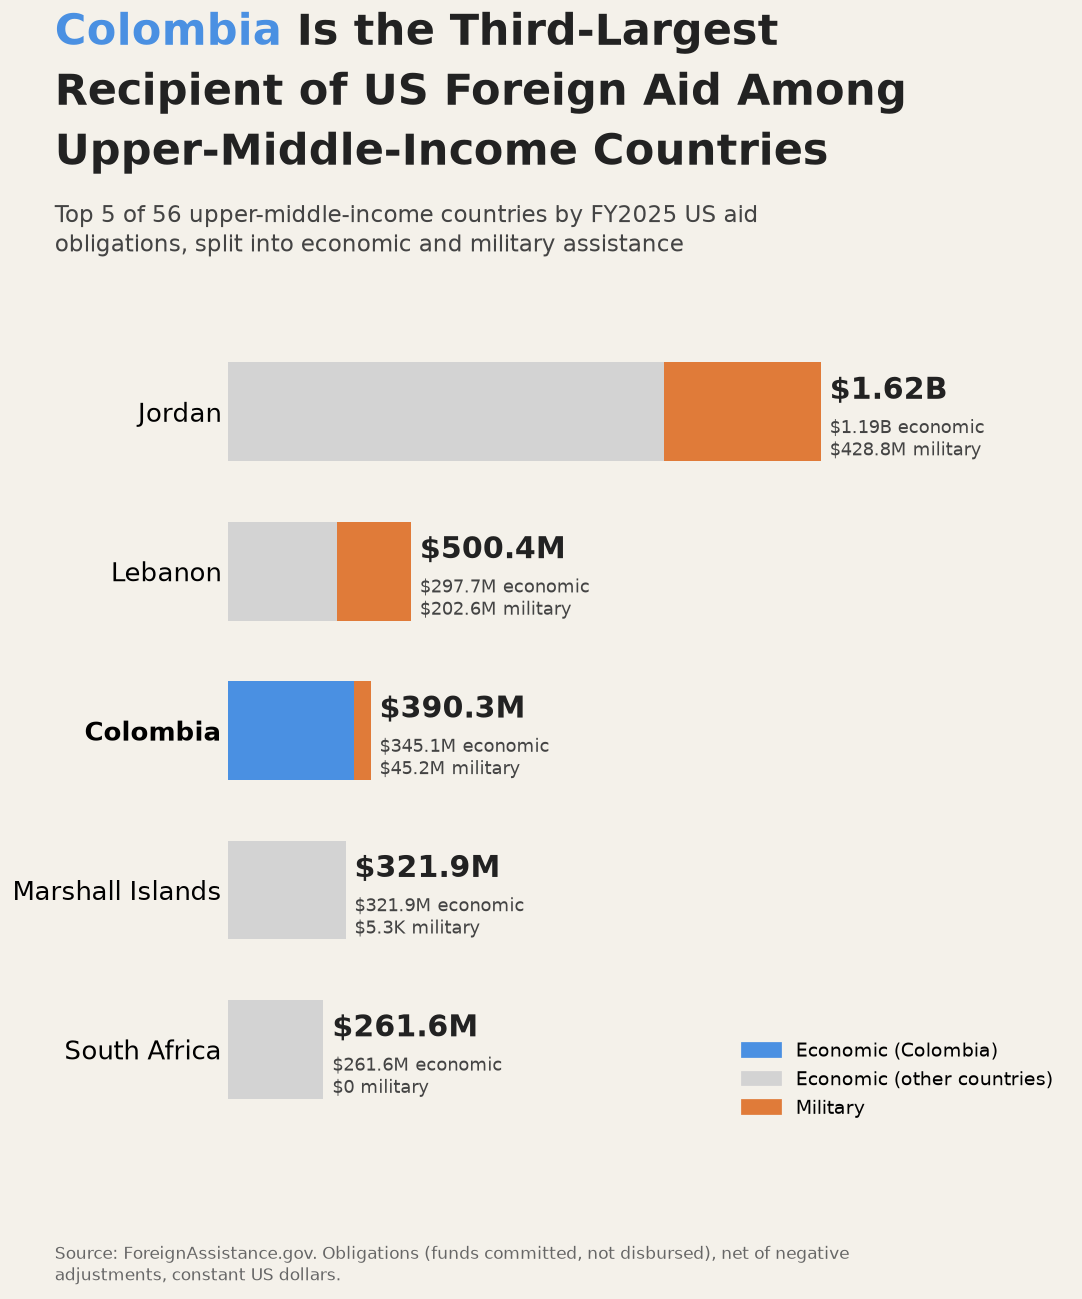

In [9]:
background = "#F4F1EA"
colombia = "#4a90e2"
military = "#E07B39"
gray = "#D3D3D3"
ink = "#222222"

TITLE = "Colombia Is the Third-Largest Recipient of US Foreign Aid Among Upper-Middle-Income Countries"
SUBTITLE = (
    "Top 5 of 56 upper-middle-income countries by FY2025 US aid obligations, "
    "split into economic and military assistance"
)
FOOTNOTE = (
    "Source: ForeignAssistance.gov. Obligations (funds committed, not disbursed), "
    "net of negative adjustments, constant US dollars."
)


def money(v):
    """Format a dollar amount, e.g. 1.62B, 428.8M, 5.3K. Never rounds across a unit."""
    for div, unit in [(1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(v) >= div:
            decimals = 2 if unit == "B" else 1
            return f"${v / div:,.{decimals}f}{unit}"
    return f"${v:,.0f}"


fig = plt.figure(figsize=(8.64, 10.8), dpi=125, facecolor=background)  # 1080 x 1350 px
ax = fig.add_axes([0.20, 0.13, 0.78, 0.60], facecolor=background)

colors = [colombia if c == "Colombia" else gray for c in df_f.index]

bars = ax.barh(df_f.index, df_f["Economic"], color=colors, height=0.62)
ax.barh(df_f.index, df_f["Military"], left=df_f["Economic"], color=military, height=0.62)

offset = df_f.Total.max() * 0.015
for b, (name, r) in zip(bars, df_f.iterrows()):
    y = b.get_y() + b.get_height() / 2
    ax.text(
        r.Total + offset, y + 0.13, money(r.Total),
        va="center", fontsize=17, fontweight="bold", color=ink,
    )
    ax.text(
        r.Total + offset, y - 0.17,
        f"{money(r.Economic)} economic\n{money(r.Military)} military",
        va="center", fontsize=10.5, color="#444444", linespacing=1.25,
    )

for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(False)

ax.set_xticks([])
ax.tick_params(axis="y", length=0, labelsize=15)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == "Colombia":
        lbl.set_fontweight("bold")
ax.set_xlim(0, df_f.Total.max() * 1.42)

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=colombia),
        plt.Rectangle((0, 0), 1, 1, color=gray),
        plt.Rectangle((0, 0), 1, 1, color=military),
    ],
    labels=["Economic (Colombia)", "Economic (other countries)", "Military"],
    frameon=False, loc="lower right", fontsize=11,
)

title_lines = textwrap.wrap(TITLE, 34)
sub = "\n".join(textwrap.wrap(SUBTITLE, 62))

renderer = fig.canvas.get_renderer()
title_kw = dict(ha="left", va="baseline", fontsize=25, fontweight="bold")
x0, y0, pitch = 0.04, 0.938, 0.0444


def text_width(s):
    t = fig.text(0, 0, s, **title_kw)
    w = t.get_window_extent(renderer).width / fig.bbox.width
    t.remove()
    return w


for i, line in enumerate(title_lines):
    y = y0 - i * pitch
    if line.startswith("Colombia"):
        rest = line[len("Colombia"):].lstrip()
        fig.text(x0, y, "Colombia", color=colombia, **title_kw)
        fig.text(x0 + text_width(line) - text_width(rest), y, rest, color=ink, **title_kw)
    else:
        fig.text(x0, y, line, color=ink, **title_kw)
fig.text(0.04, 0.822, sub, ha="left", va="top", fontsize=13, color="#444444",
         linespacing=1.3)
fig.text(0.04, 0.05, "\n".join(textwrap.wrap(FOOTNOTE, 95)), ha="left", va="top",
         fontsize=9.5, color="#666666", linespacing=1.3)

plt.show()